# 8.4 Фононы Si с готовым NEP / 使用已有 NEP 计算硅的声子
Используем `data/POSCAR-Si` и `data/Si_NEP.txt`, скопированные из материалов курса. Потенциал здесь не обучаем.
使用课程已有结构和势文件，本例不训练 NEP。需要 ASE、Calorine、Phonopy 和 Seekpath；这个 Notebook 不需要 PyTorch。

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from calorine.calculators import CPUNEP
from calorine.tools import relax_structure, get_force_constants
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})
blue, red = "#356AE6", "#D94F65"
candidates = [Path("data"), Path("08-modern-computational-physics/data")]
data = next((p.resolve() for p in candidates if (p/"Si_NEP.txt").exists()), None)
if data is None:
    raise FileNotFoundError("Open this notebook from its folder; keep the data folder beside it.")
structure = read(data / "POSCAR-Si")
calculator = CPUNEP(str(data / "Si_NEP.txt"))
structure.calc = calculator
initial_volume = structure.get_volume()
relax_structure(structure, fmax=1e-4, logfile=None)
max_force = np.linalg.norm(structure.get_forces(), axis=1).max()
print("Primitive atoms:", len(structure))
print(f"Volume: {initial_volume:.6f} -> {structure.get_volume():.6f} A^3")
print(f"Energy: {structure.get_potential_energy():.8f} eV; max force: {max_force:.3e} eV/A")

Matplotlib is building the font cache; this may take a moment.


Primitive atoms: 2
Volume: 40.104529 -> 40.630161 A^3
Energy: -9.25449826 eV; max force: 7.729e-15 eV/A


## Энергия и сила / 能量与力
Проверяем $F_x=-\partial E/\partial x$ конечной разностью энергии для смещённого атома. Это проверка согласованности, а не сравнение с DFT.
对位移后的原子，用能量的中心差分检查力，检验能量与力的一致性，并不代表与 DFT 精度一致。

NEP force: -0.24855099; energy difference: -0.24855099 eV/A


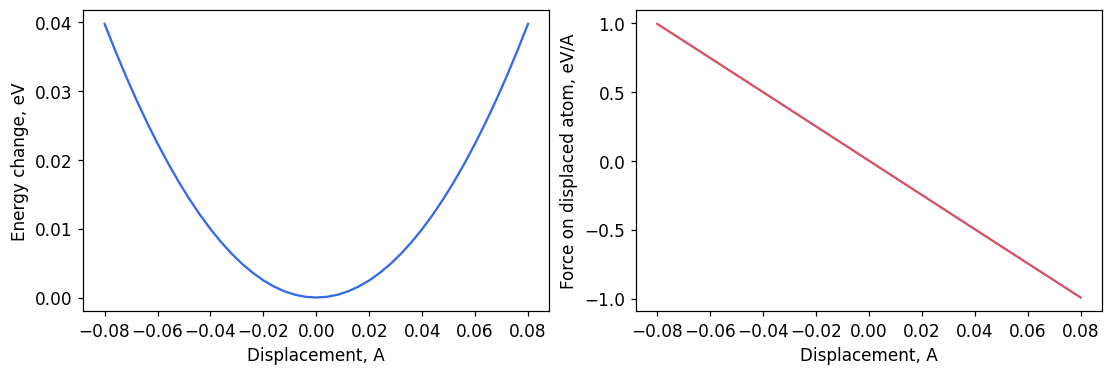

In [2]:
probe = structure.repeat((2, 2, 2))
probe.calc = calculator
base = probe.positions.copy()
probe.positions[0, 0] += 0.02
force = probe.get_forces()[0, 0]
center = probe.positions.copy()
epsilon = 1e-5
energies = []
for sign in [-1, 1]:
    probe.positions = center.copy()
    probe.positions[0, 0] += sign * epsilon
    energies.append(probe.get_potential_energy())
force_fd = -(energies[1] - energies[0]) / (2 * epsilon)
print(f"NEP force: {force:.8f}; energy difference: {force_fd:.8f} eV/A")
displacements = np.linspace(-0.08, 0.08, 41)
energy_curve, force_curve = [], []
for displacement in displacements:
    probe.positions = base.copy()
    probe.positions[0, 0] += displacement
    energy_curve.append(probe.get_potential_energy())
    force_curve.append(probe.get_forces()[0, 0])
energy_curve = np.asarray(energy_curve)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
axes[0].plot(displacements, energy_curve-energy_curve[20], color=blue)
axes[0].set(xlabel="Displacement, A", ylabel="Energy change, eV")
axes[1].plot(displacements, force_curve, color=red)
axes[1].set(xlabel="Displacement, A", ylabel="Force on displaced atom, eV/A")
plt.show()

## Силовые постоянные / 力常数
Суперячейка 4 × 4 × 4, смещения 0.01 Å. После расчёта симметризуем силовые постоянные, включая правило акустических сумм. Сохраняем исходные частоты Γ для сравнения.
使用 4 × 4 × 4 超胞与 0.01 Å 位移。先记录原始 Γ 点频率，再对力常数施加对称性和声学求和规则。

In [3]:
phonon = get_force_constants(structure, calculator, [4, 4, 4],
    kwargs_generate_displacements={"distance": 0.01})
gamma_raw = phonon.get_frequencies([0, 0, 0])
phonon.symmetrize_force_constants()
gamma = phonon.get_frequencies([0, 0, 0])
print("Gamma before symmetrization, THz:", gamma_raw)
print("Gamma after symmetrization, THz:", gamma)
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="dict interface is deprecated.*",
                            category=DeprecationWarning, module="seekpath.*")
    phonon.auto_band_structure(npoints=61)
bands = phonon.get_band_structure_dict()
phonon.run_mesh([30, 30, 30])
mesh = phonon.get_mesh_dict()
minimum = min(float(f.min()) for f in bands["frequencies"])
maximum = max(float(f.max()) for f in bands["frequencies"])
minimum = min(minimum, float(mesh["frequencies"].min()))
maximum = max(maximum, float(mesh["frequencies"].max()))
phonon.run_total_dos(sigma=0.08, freq_min=min(-0.5, minimum-0.5),
                    freq_max=maximum+0.5, freq_pitch=0.02)
dos = phonon.get_total_dos_dict()
dos_integral = np.trapezoid(dos["total_dos"], dos["frequency_points"])
print(f"Branches: {bands['frequencies'][0].shape[1]}; minimum: {minimum:.5f} THz")
print(f"DOS integral: {dos_integral:.5f}; expected modes: {3*len(phonon.primitive)}")

Gamma before symmetrization, THz: [2.65132229e-07 3.21089523e-07 3.30969770e-07 1.43229273e+01
 1.43229273e+01 1.43229273e+01]
Gamma after symmetrization, THz: [3.28945703e-07 3.54969514e-07 3.62501448e-07 1.43229273e+01
 1.43229273e+01 1.43229273e+01]
Branches: 6; minimum: 0.00000 THz
DOS integral: 6.00000; expected modes: 6


## Дисперсия и плотность состояний / 色散与态密度
Seekpath задаёт путь в примитивной ячейке; Phonopy сохраняет разрывы пути. Отрицательные частоты, если они есть, не скрываем.
Seekpath 生成原胞倒空间路径，Phonopy 保留路径间的断开。若出现负频率，不裁剪隐藏。声子计算基于谐波近似。

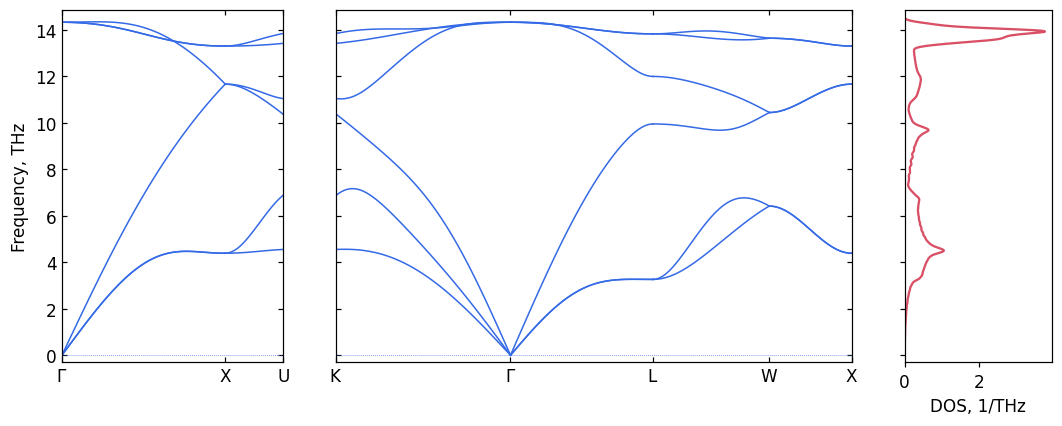

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharey=True,
                         gridspec_kw={"width_ratios": [1.5, 3.5, 1], "wspace": 0.18})
phonon.band_structure.plot(axes[:2])
for ax in axes[:2]:
    for line in ax.lines:
        line.set_color(blue)
axes[0].set_ylabel("Frequency, THz")
axes[2].plot(dos["total_dos"], dos["frequency_points"], color=red)
axes[2].set(xlabel="DOS, 1/THz", xlim=(0, None))
axes[0].set_ylim(min(-0.3, minimum-0.1), maximum+0.5)
fig.subplots_adjust(bottom=0.16, left=0.08, right=0.98, top=0.96)
plt.show()

## Проверка размера суперячейки / 超胞尺寸检查
Сравним 4³ и 5³ в нескольких точках. Это локальная проверка чувствительности; для исследования нужно также проверять смещение и сетку DOS.
比较 4³ 与 5³ 超胞在几个 q 点的差异。这是局部敏感性检查；实际研究还需要检查位移大小和 DOS 网格。

In [5]:
phonon5 = get_force_constants(structure, calculator, [5, 5, 5],
    kwargs_generate_displacements={"distance": 0.01})
phonon5.symmetrize_force_constants()
qpoints = [[0, 0, 0], [0.5, 0, 0.5], [0.5, 0.5, 0.5]]
differences = []
for q in qpoints:
    difference = np.max(abs(phonon.get_frequencies(q) - phonon5.get_frequencies(q)))
    differences.append(difference)
    print(f"q={q}: max |f(4^3)-f(5^3)| = {difference:.6f} THz")

q=[0, 0, 0]: max |f(4^3)-f(5^3)| = 0.000000 THz
q=[0.5, 0, 0.5]: max |f(4^3)-f(5^3)| = 0.000000 THz
q=[0.5, 0.5, 0.5]: max |f(4^3)-f(5^3)| = 0.000000 THz


Документация / 文档：[Calorine](https://calorine.materialsmodeling.org/reference/tools.html), [Phonopy](https://phonopy.github.io/phonopy/formulation.html).
Частоты относятся к данному файлу потенциала и релаксированной структуре; точность относительно эксперимента здесь не установлена.
结果对应本势文件和弛豫后的结构，本例尚未通过实验数据验证精度。